# **Data-Driven modeling of a linear Mass-Spring-Damper System using ML**
## 1. Introduction
In this project, we study the dynamics of mechanical systems using numerical simulations, data generation and machine learning.

We begin with a classical mass-spring-damper system as a simple linear test case for numerical simulation and data-driven modeling.

The governing equation is:

$$
m\ddot{x}+c\dot{x}+kx = 0
$$
Note: we use random values for the system parameters

In [1]:
m = 1
c = 0.5
k = 4
print('Mass:',m)
print('Damping Coefficient:',c)
print('Stiffness:',k)

Mass: 1
Damping Coefficient: 0.5
Stiffness: 4


---
## 2. State-Space Representation

The original model is a second-order differential equation.
For numerical simulation and control applications, we rewrite
the system in first-order state-space form.

Define the state variables as:

$$
x_1=x
$$

and

$$
x_2=\dot{x}
$$

Therefore:

$$
\dot{x}_1=x_2
$$

and

$$
\dot{x}_2
=
-\frac{k}{m}x_1
-\frac{c}{m}x_2
$$

The state-space representation can be written as:

$$
\dot{X}=AX
$$

where

$$
X=
\begin{bmatrix}
x_1\\
x_2
\end{bmatrix}
$$

and

$$
A=
\begin{bmatrix}
0 & 1\\
-\frac{k}{m} & -\frac{c}{m}
\end{bmatrix}.
$$

In [2]:
import numpy as np

A = np.array([
    [0, 1],
    [-k / m, -c / m]
])

print("State-space matrix A:")
print(A)

State-space matrix A:
[[ 0.   1. ]
 [-4.  -0.5]]


## 3. Eigenvalue Analysis

The eigenvalues are obtained from:

$$
\det(\lambda I-A)=0
$$

For a continuous-time linear system, the real parts of the
eigenvalues determine stability.

In [3]:
eigenvalues, eigenvectors = np.linalg.eig(A)

print("Eigenvalues:")
print(eigenvalues)

Eigenvalues:
[-0.25+1.98431348j -0.25-1.98431348j]


In [4]:
def dynamics(t, X):
    x1 = X[0]
    x2 = X[1]

    d_x1 = x2
    d_x2 = -(k / m) * x1 - (c / m) * x2

    return d_x1, d_x2

---
## 4. Numerical Simulation

To solve the differential equations numerically, we use
the `solve_ivp` function from SciPy.

The initial condition is:

$$
x(0)=1
$$

$$
\dot{x}(0)=0
$$

Therefore, the initial state is:

$$
X(0)=
\begin{bmatrix}
1\\
0
\end{bmatrix}.
$$

In [5]:
from scipy.integrate import solve_ivp

x0 = [1.0, 0.0]

t_start = 0.0
t_end = 10.0

t_eval = np.linspace(t_start, t_end, 1000)

In [6]:
sol = solve_ivp(
    dynamics,
    [t_start, t_end],
    x0,
    t_eval=t_eval
)

In [7]:
t = sol.t

x = sol.y[0]

d_x = sol.y[1]
print("Number of time points:", len(t))
print("Initial position:", x[0])
print("Final position:", x[-1])
print("Initial velocity:", d_x[0])
print("Final velocity:", d_x[-1])

Number of time points: 1000
Initial position: 1.0
Final position: 0.05304549179274632
Initial velocity: 0.0
Final velocity: -0.13838481876515613


---
## 5. Position Response

The displacement response of the system is plotted as a
function of time.

Because the system is damped and stable, the oscillation
amplitude should decrease with time.

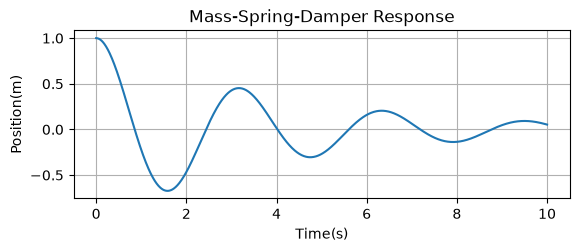

In [8]:
import matplotlib.pyplot as plt

plt.subplot(2,1,1)
plt.plot(t, x)
plt.xlabel('Time(s)')
plt.ylabel('Position(m)')
plt.title('Mass-Spring-Damper Response')
plt.grid()

## 6. Velocity Response

The velocity of the system is plotted as a function of time

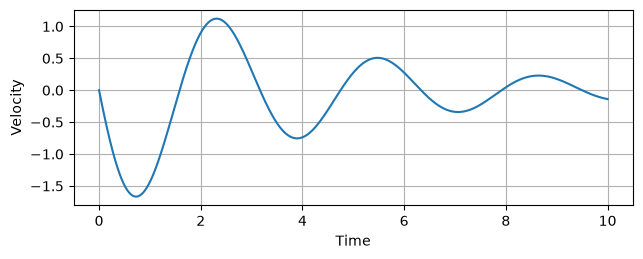

In [9]:
plt.subplot(2,1,2)
plt.plot(t, d_x)
plt.xlabel('Time')
plt.ylabel('Velocity')
plt.grid()
plt.tight_layout()
plt.show()

## 7. Phase Portrait

The phase portrait represents the trajectory of the system
in the state space.

The horizontal axis represents the position $x$, while the
vertical axis represents the velocity $\dot{x}$.

For this damped and stable system, the trajectory should
converge toward the equilibrium point:
$$
(x, \dot{x}) = (0, 0)
$$

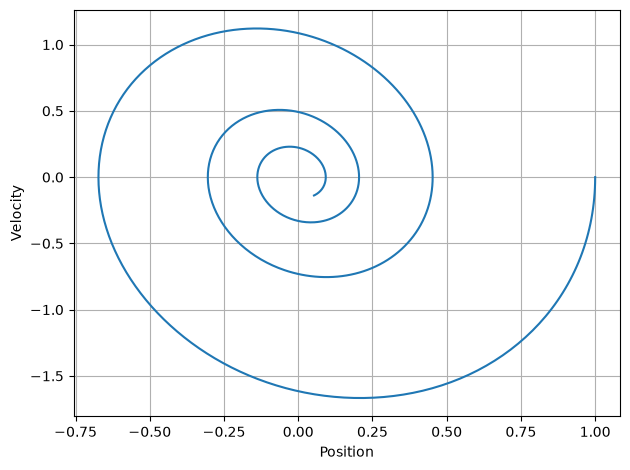

In [10]:
plt.plot(x, d_x)
plt.xlabel('Position')
plt.ylabel('Velocity')
plt.grid()
plt.tight_layout()
plt.show()

## 8. Energy Analysis

The mechanical energy of the system consists of kinetic and
potential energy.

The kinetic energy is:

$$
T=\frac{1}{2}m\dot{x}^2
$$

The potential energy stored in the spring is:

$$
V=\frac{1}{2}kx^2
$$a

Therefore, the total mechanical energy is:
$$
E = T+V
$$
$$
E =\frac{1}{2}m\dot{x}^2+\frac{1}{2}kx^2
$$
Since the system contains a damper, mechanical energy decreases over time.

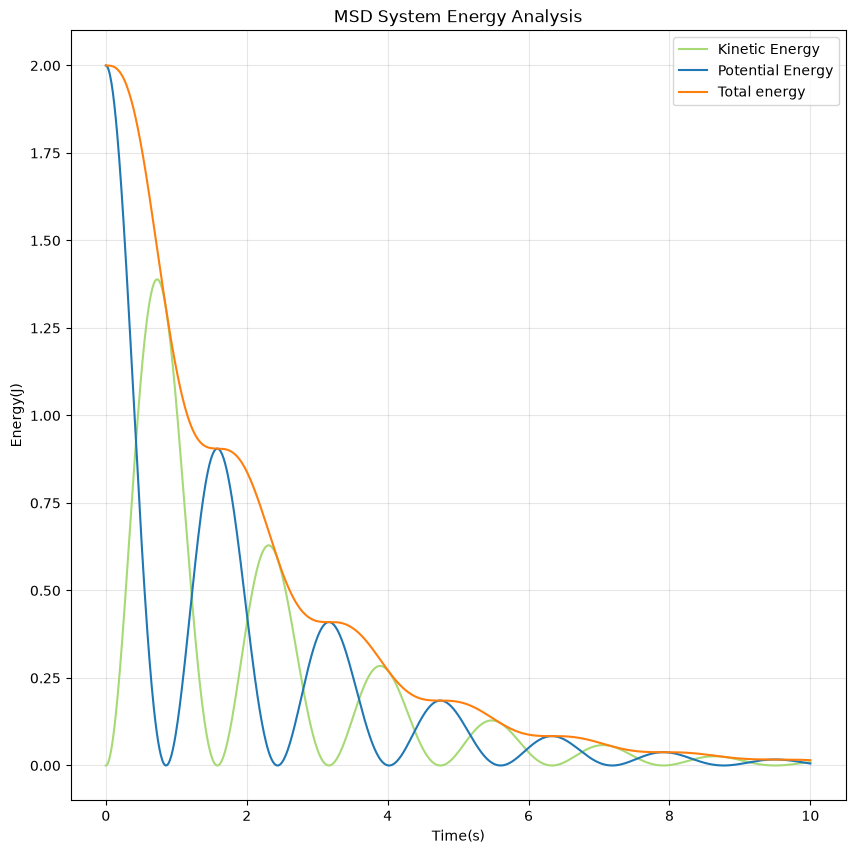

In [11]:
KE = 0.5*m*(d_x)**2
PE = 1/2*k*x**2
E = PE + KE

plt.figure(figsize=(10, 10))
plt.plot(t, KE, label='Kinetic Energy', color='#a7d975')
plt.plot(t, PE, label='Potential Energy')
plt.plot(t, E, label='Total energy')

plt.xlabel('Time(s)')
plt.ylabel('Energy(J)')
plt.title('MSD System Energy Analysis')

plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 9. Acceleration

The acceleration of the system can be obtained from the equation of motion:

$$
\ddot{x} = -\frac{k}{m}x-\frac{c}{m}\dot{x}
$$

We will examine the acceleration values ​​obtained from the equation and then compare them with the machine learning data.

In [12]:
# Let a denote acceleration
a = -(k / m) * x - (c / m) * d_x
print("First 5 acceleration values:", a[:5])

First 5 acceleration values: [-4.         -3.97923109 -3.95697503 -3.93324809 -3.90806622]


## 10. Constructing the Input and Target Data

For supervised learning, the dataset is divided into input variables and target variables.

The input consists of the current position and velocity:

$$
X_{\text{data}}
=
\begin{bmatrix}
x_0 & \dot{x}_0 \\
x_1 & \dot{x}_1 \\
\vdots & \vdots \\
x_{999} & \dot{x}_{999}
\end{bmatrix}.
$$

The target consists of the time derivatives of the state:

$$
Y_{\text{data}}
=
\begin{bmatrix}
\dot{x}_0 & \ddot{x}_0 \\
\dot{x}_1 & \ddot{x}_1 \\
\vdots & \vdots \\
\dot{x}_{999} & \ddot{x}_{999}
\end{bmatrix}.
$$

Therefore, each row represents one state of the mechanical system and its corresponding state derivative.

In [29]:
X_data = np.column_stack((x, d_x))
Y_data = np.column_stack((d_x, a))

### 10.1 Inspecting the Dataset

The dimensions and several initial samples of the input and target datasets are inspected to verify that the dataset has been constructed correctly.

In [30]:
print("X_data shape:", X_data.shape)
print("Y_data shape:", Y_data.shape)

print("\nFirst 5 input samples:")
print(X_data[:5])

print("\nFirst 5 target samples:")
print(Y_data[:5])

X_data shape: (1000, 2)
Y_data shape: (1000, 2)

First 5 input samples:
[[ 1.          0.        ]
 [ 0.99979994 -0.03993734]
 [ 0.99920117 -0.07965932]
 [ 0.99820592 -0.11915119]
 [ 0.99681647 -0.15839931]]

First 5 target samples:
[[ 0.         -4.        ]
 [-0.03993734 -3.97923109]
 [-0.07965932 -3.95697503]
 [-0.11915119 -3.93324809]
 [-0.15839931 -3.90806622]]


### 10.2 Visualizing the Dataset

Before training a machine learning model, it is useful to visualize
the relationship between the input states and the corresponding
state derivatives.

The first input variable is the position $x$, and the second input
variable is the velocity $\dot{x}$.

The target variables are $\dot{x}$ and $\ddot{x}$.

These plots help us understand the structure of the data before
applying a machine learning model.

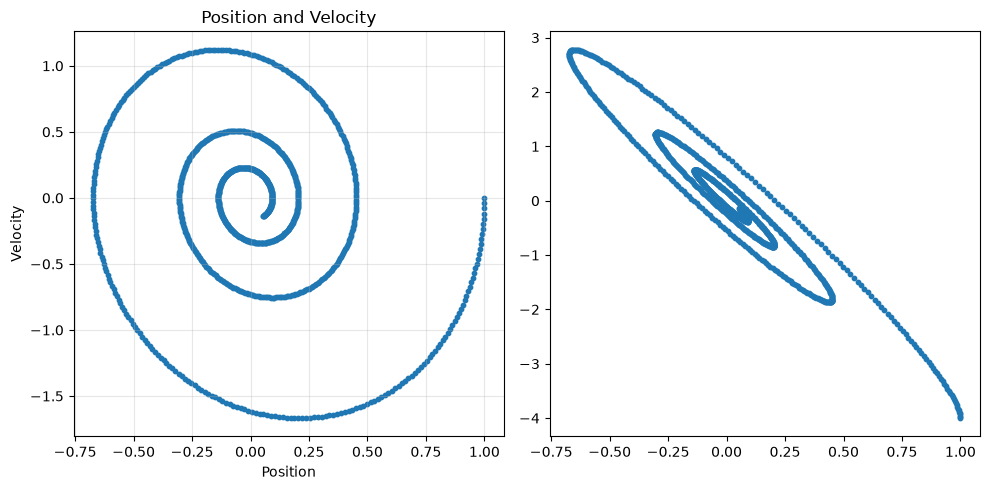

In [31]:
plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.scatter(X_data[:,0], Y_data[:,0], s=10)
plt.xlabel('Position')
plt.ylabel('Velocity')
plt.title('Position and Velocity')
plt.grid(True, alpha=0.3)
plt.subplot(1, 2, 2)
plt.scatter(X_data[:, 0], Y_data[:, 1], s=10)
plt.tight_layout()
plt.show()


### 10.3 Train/Test Split

Before training a machine learning model, the dataset is divided
into training and testing subsets.

The training data are used to learn the relationship between the
system state and its time derivatives.

The testing data are kept separate and are used later to evaluate
the performance of the trained model.

In this project, 80% of the data are used for training and 20%
are used for testing.

In [32]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(
    X_data,
    Y_data,
    test_size=0.2,
    random_state=50
)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Y_train shape:", Y_train.shape)
print("Y_test shape:", Y_test.shape)


X_train shape: (800, 2)
X_test shape: (200, 2)
Y_train shape: (800, 2)
Y_test shape: (200, 2)


### 10.4 Feature Scaling

Machine learning models can be sensitive to the numerical scale of
their input variables.

In our dataset, the input variables are position $x$ and velocity
$\dot{x}$.

Feature scaling transforms the input variables to a comparable
numerical range.

Here, we use standardization:

$$
z = \frac{x-\mu}{\sigma}
$$

where $\mu$ is the mean of the feature and $\sigma$ is its standard
deviation.

The scaling parameters are calculated using the training data only.
The same transformation is then applied to the test data.

In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First 5 scaled training samples:")
print(X_train_scaled[:5])

First 5 scaled training samples:
[[ 0.048749    0.46710663]
 [-0.91535027  0.38891445]
 [ 0.64058722  1.54039683]
 [-1.19289001 -1.78148771]
 [ 0.57349461 -0.07580639]]


## 11. First Machine Learning Model

We now train a machine learning model to learn the relationship
between the state of the mechanical system and its state derivatives.

The input to the model is:

$$
X =
\begin{bmatrix}
x & \dot{x}
\end{bmatrix}
$$

and the target is:

$$
Y =
\begin{bmatrix}
\dot{x} & \ddot{x}
\end{bmatrix}.
$$

We begin with a Linear Regression model because the current
mass-spring-damper system is linear.

The model attempts to learn a mapping of the form:

$$
Y = XW + b
$$

where $W$ contains the model coefficients and $b$ is the bias term.

In [34]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

### 11.1 Training the Model

The model is trained using the training dataset.

The input variables are the system states, while the target variables
are the corresponding state derivatives.

The model learns the coefficients that minimize the prediction error
between the predicted and actual target values.

In [35]:
model.fit(X_train_scaled, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2, 2)","[[ 0. , 0.63], [-1.31,-0.31]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](2,)","[-0.09, 0.02]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[31.44,24.72]"


### 11.2 Making Predictions

After training, the model is used to predict the state derivatives
of the test dataset.

The test inputs were not used during model training.

Therefore, the predictions provide an initial evaluation of how well
the learned model generalizes to unseen data.

In [36]:
Y_pred = model.predict(X_test_scaled)

print("Y_pred shape:", Y_pred.shape)
print("\nFirst 5 predicted samples:")
print(Y_pred[:5])

Y_pred shape: (200, 2)

First 5 predicted samples:
[[ 0.00482496 -1.81308951]
 [-0.19214181  1.25526921]
 [ 0.2255001   0.08842453]
 [-0.4251009  -3.69259196]
 [-0.09514149 -0.26463473]]


### 11.3 Model Evaluation

After training the model, its predictions are compared with the
actual target values from the test dataset.

Several evaluation metrics can be used to quantify the prediction
error.

In this project, we use Mean Absolute Error (MAE), Mean Squared
Error (MSE), Root Mean Squared Error (RMSE), and the coefficient
of determination $R^2$.

In [37]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 1.9433239739630182e-16
MSE : 7.633354121471432e-32
RMSE: 2.7628525334283464e-16
R²  : 1.0


### 11.4 Evaluation of Individual Outputs

The target contains two state derivatives:

$$
Y =
\begin{bmatrix}
\dot{x} & \ddot{x}
\end{bmatrix}
$$

Therefore, the prediction error is evaluated separately for
velocity and acceleration.

In [38]:
mae_velocity = mean_absolute_error(
    Y_test[:, 0],
    Y_pred[:, 0]
)

mae_acceleration = mean_absolute_error(
    Y_test[:, 1],
    Y_pred[:, 1]
)

print("MAE - Velocity:", mae_velocity)
print("MAE - Acceleration:", mae_acceleration)

MAE - Velocity: 1.5210055437364646e-16
MAE - Acceleration: 2.365642404189572e-16


### 11.5 True vs Predicted Values

The predicted state derivatives are compared with the true values
from the test dataset.

If the model performs well, the predicted values should be close
to the true values.

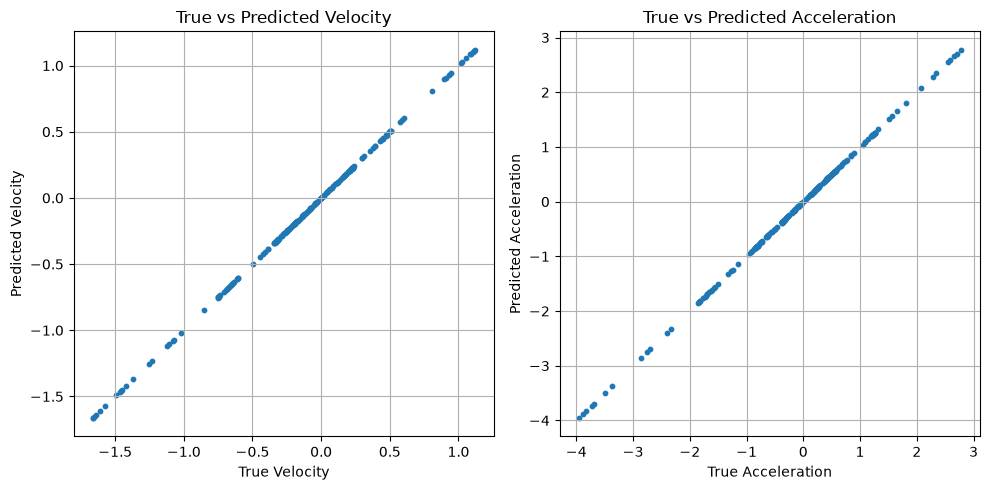

In [39]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(Y_test[:, 0], Y_pred[:, 0], s=10)
plt.xlabel('True Velocity')
plt.ylabel('Predicted Velocity')
plt.title('True vs Predicted Velocity')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(Y_test[:, 1], Y_pred[:, 1], s=10)
plt.xlabel('True Acceleration')
plt.ylabel('Predicted Acceleration')
plt.title('True vs Predicted Acceleration')
plt.grid(True)

plt.tight_layout()
plt.show()

## 12. Physics vs Machine Learning

The physical model of the mass-spring-damper system is known:

$$
\dot{x} = \dot{x}
$$

$$
\ddot{x} = -4x - 0.5\dot{x}
$$

Therefore, the corresponding state-space matrix is:

$$
A =
\begin{bmatrix}
0 & 1\\
-4 & -0.5
\end{bmatrix}.
$$

The Linear Regression model has learned a mapping from the
system state to its time derivatives directly from the generated data.

In this section, the coefficients learned by the machine learning
model are compared with the coefficients of the physical model.

In [40]:
print("Learned coefficients:")
print(model.coef_)

print("\nLearned intercept:")
print(model.intercept_)

Learned coefficients:
[[ 6.28036983e-17  6.29676535e-01]
 [-1.30667756e+00 -3.14838268e-01]]

Learned intercept:
[-0.08664929  0.0212166 ]


### 12.1 Recovering the Physical Model from the Learned Model

Because the input variables were standardized before training,
the coefficients learned by the Linear Regression model are expressed
in the scaled input space.

To compare the learned model with the physical equations, the learned
coefficients must be transformed back to the original physical scale.

The original physical model is:

$$
\dot{x} = 0x + 1\dot{x}
$$

$$
\ddot{x} = -4x - 0.5\dot{x}
$$

Therefore, the corresponding physical coefficient matrix is:

$$
A =
\begin{bmatrix}
0 & 1\\
-4 & -0.5
\end{bmatrix}.
$$

In [41]:
physical_coefficients = model.coef_ / scaler.scale_

print("Recovered physical coefficients:")
print(physical_coefficients)

Recovered physical coefficients:
[[ 1.92254617e-16  1.00000000e+00]
 [-4.00000000e+00 -5.00000000e-01]]


### 12.2 Comparison of Physical and Learned Coefficients

The recovered coefficients of the machine learning model are compared
with the coefficients of the physical model.

Since the mass-spring-damper system is linear, the learned model should
recover the same state-space coefficients as the original physical model.

In [42]:
A_physical = A

A_ml = physical_coefficients

print("Physical coefficient matrix:")
print(A_physical)

print("\nMachine learning coefficient matrix:")
print(A_ml)

print("\nAbsolute difference:")
print(np.abs(A_physical - A_ml))

Physical coefficient matrix:
[[ 0.   1. ]
 [-4.  -0.5]]

Machine learning coefficient matrix:
[[ 1.92254617e-16  1.00000000e+00]
 [-4.00000000e+00 -5.00000000e-01]]

Absolute difference:
[[1.92254617e-16 4.44089210e-16]
 [0.00000000e+00 5.55111512e-16]]


In [ ]:
# Measuring the maximum error 
coefficient_error = np.max(A_physical - A_ml)


print("Maximum coefficient error:", coefficient_error)

Maximum coefficient error: 5.551115123125783e-16


## 13. Final Comparison

The physical model and the machine learning model are compared
using their state-space coefficient matrices.

The physical model is defined as:

$$
\dot{X}=AX
$$

with:

$$
A=
\begin{bmatrix}
0 & 1\\
-4 & -0.5
\end{bmatrix}.
$$

The machine learning model is trained using simulated data and
attempts to recover the same relationship between the system state
and its time derivatives.

The comparison shows how accurately the machine learning model
can recover the known physical dynamics from data.

In [45]:
import pandas as pd

comparison = pd.DataFrame(
    {
        "Physical": A_physical.flatten(),
        "Machine Learning": A_ml.flatten()
    },
    index=[
        "x -> dx/dt",
        "v -> dx/dt",
        "x -> d2x/dt2",
        "v -> d2x/dt2"
    ]
)

comparison["Absolute Error"] = np.abs(
    comparison["Physical"] - comparison["Machine Learning"]
)

comparison

,Physical,Machine Learning,Absolute Error
x -> dx/dt,0.0,1.922546e-16,1.922546e-16
v -> dx/dt,1.0,1.000000e+00,4.440892e-16
x -> d2x/dt2,-4.0,-4.000000e+00,0.000000e+00
v -> d2x/dt2,-0.5,-5.000000e-01,5.551115e-16


# 14. Conclusion

In this project, a linear mass-spring-damper system was studied
using Python-based numerical simulation and machine learning.

The physical system was first formulated in state-space form and
numerically simulated using SciPy. The resulting simulation data
were then used to construct a supervised machine learning dataset.

A Linear Regression model was trained to learn the relationship
between the system states and their time derivatives.

The model was evaluated using MAE, MSE, RMSE, and $R^2$ metrics.
The learned coefficients were then transformed back to the original
physical scale and compared with the known physical model.

The results showed that the machine learning model successfully
recovered the coefficients of the physical dynamics with a very
small numerical error.

Therefore, this project demonstrates a basic data-driven approach
to modeling mechanical dynamical systems using Python and machine
learning.